In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

import numpy as np

from mpi4py import MPI
from dolfinx import fem, mesh

from BaseModels import GaussianLikelihood
from FenicsxModels.FenicsxPriors import MultiFieldPrior
from FenicsxModels.PAISolver import PAISolver
from FenicsxModels import Helpers


/Users/tcui0786/Work/DeepTransport/PyFInS-public


In [2]:
N = 24

domain = mesh.create_rectangle(
    MPI.COMM_WORLD,
    ((0.0, 0.0), (4.0, 2.0)),
    (N*2, N),
    cell_type=mesh.CellType.triangle,
)

Vh = fem.functionspace(domain, ("CG", 1))

# Time steps for acoustic wave eqn #
t_init, t_final, dt = 0.0, 30e-6, 5e-8
simulation_times = np.arange(t_init, t_final + 0.5*dt, dt)

wavelength=800.0
n_gates=20

roi = lambda x: np.where(((x[0]-3.0)**2)/(0.5**2)+((x[1]-1.0)**2)/(0.3**2) <= 1.0, 1.0, 0.0) # Region of interest for sO2 QoI

model = PAISolver(
    domain,
    Vh,
    simulation_times,
    wavelength=wavelength,
    roi=roi,
    n_gates=n_gates,
    design_probe=False,
    xs_default=2.0,
    probe_y=2.0,
    qoi_type="sO2",
    high_accuracy=True, # turn off for reducing Krylov solves
    acoustic_check_tolerance=1.0e-8,
)

Acoustic observation operator: relative check error=2.597472e-10, passed=True


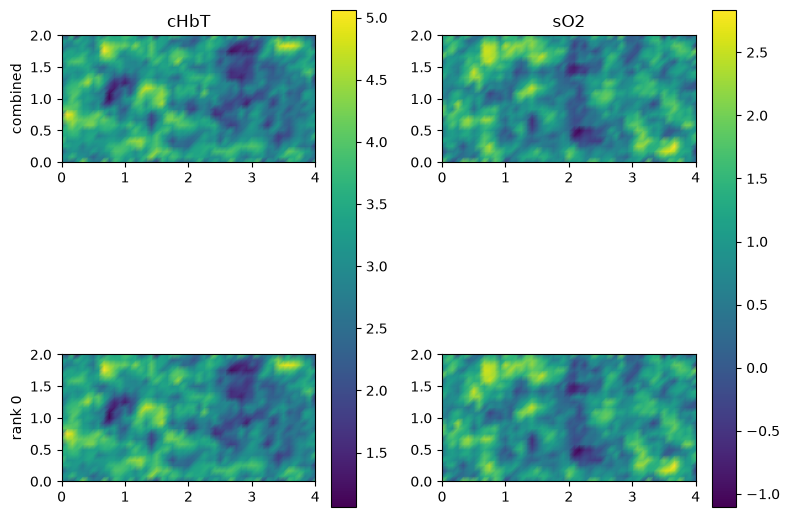

In [3]:
rho = 0.5

correlation = np.array([
    [1.0, rho],
    [rho, 1.0],
])

prior = MultiFieldPrior(
    Vh,
    sigma=[1.0, 1.0],
    ell=[0.5, 0.5],
    mu=[np.log(20.0), np.log(0.7/0.3)],
    correlation=correlation,
    names=["cHbT", "sO2"],
    seed=12345,
)

m_true = prior.sample()
Helpers.plot_prior_draw_mpi(
    prior,
    m_true,
    filename=None,
    show=True,
)

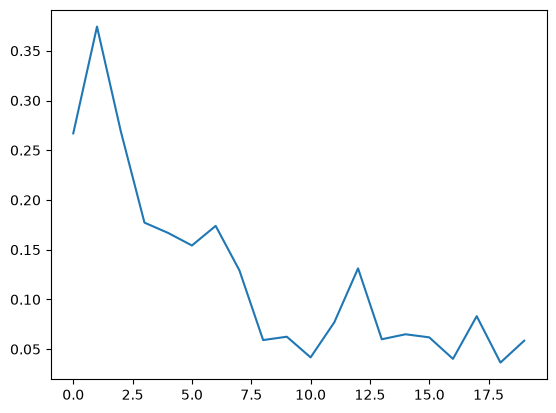

20


In [4]:
from matplotlib import pyplot as plt

y, _ = model.solve(m_true)

sig2noise = 5
sigma = np.abs(y).mean()/sig2noise
fake_data = y + np.random.normal(0, sigma, size=y.shape)
like = GaussianLikelihood(fake_data, sigma)

plt.plot(fake_data)
plt.show()
print(like.n_obs)

In [ ]:
from FenicsxInference import LikelihoodInformedSMC, LikelihoodInformedSubspace
from InferenceTools.TransitionKernels import OneStepKernel

kernel = OneStepKernel(
        type="OW",
        sigma=-3.0,
        adapt=True,
        nbatch=1,
)

LIS = LikelihoodInformedSubspace(prior=prior, epsilon=0.1)

sampler = LikelihoodInformedSMC(
        prior,
        model,
        like,
        LIS,
        kernel,
        max_iter=100,
        n_samples=1000,
        n_mutation_steps=20,
        n_final_mutation_steps=100,
        ess_tol=0.5,
        min_beta=1e-6,
        pm_sample_size=5,
)

sampler.iterate()

model+adjoint:  10%|▉         | 99/1000 [00:07<01:06, 13.45it/s]